## Load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

from sklearn.linear_model import LogisticRegression
import warnings
from lifelines.exceptions import StatisticalWarning
import subprocess

warnings.filterwarnings("ignore", category=StatisticalWarning)


df = pd.read_csv('analysis_ready.csv')
df.shape

(1858, 357)

In [45]:
covariates = [
    'AGE', 'SEX', 'RACE',
    'INSURANCE_STATUS',
    'Charlson_Deyo_Score', 'HISTOLOGY', 'COMBINED_STAGE_GROUP',
    'YEAR_OF_DIAGNOSIS', 'Surgery', 'Radiation_Therapy'
]

### Filter out same day and early stage

In [46]:
df = df[df['sequence_group'].isin([0, 1])]
df = df[df['COMBINED_STAGE_GROUP'].isin([3, 4])]

In [47]:
df['sequence_group'].value_counts(), df.shape

(sequence_group
 0    930
 1    205
 Name: count, dtype: int64,
 (1135, 357))

## Survival Functions

### Survival analysis

In [48]:
def weighted_risk_counts(df, time_points, group_value):
    risk_counts = []
    group = df[df['sequence_group'] == group_value]
    for t in time_points:
        still_at_risk = group[group['time'] >= t]['iptw_weight'].sum()
        risk_counts.append(int(round(still_at_risk)))
    return risk_counts

def risk_counts(df, time_points, group_value):
    risk_counts = []
    group = df[df['sequence_group'] == group_value]
    for t in time_points:
        still_at_risk = group[group['time'] >= t].shape[0]
        risk_counts.append(still_at_risk)
    return risk_counts

def survival_with_ci(kmf, time):
    surv = kmf.predict(time)
    
    closest_idx = kmf.confidence_interval_.index.get_indexer([time], method='nearest')[0]
    ci = kmf.confidence_interval_.iloc[closest_idx]

    lower = ci.iloc[0]
    upper = ci.iloc[1]

    # sanity check for CI
    if (upper == 1.0 and lower == 1.0) or (upper == 0.0 and lower == 0.0):
        return surv, None, None  # invalid or non-estimable CI

    return surv, lower, upper

def plot_survival(kmf_tace, kmf_sys, hr, ci_low, ci_high, p_val, surv_text, tace_risk, sys_risk, time_grid, weighted=False, file_name=None):
    fig = plt.figure(figsize=(9, 7))
    gs = gridspec.GridSpec(2, 1, height_ratios=[4, 0.75], hspace=0.05)

    # KM Plot
    ax_km = plt.subplot(gs[0])
    kmf_tace.plot(ax=ax_km, ci_show=True, color="#ff7f0e", linewidth=3)
    kmf_sys.plot(ax=ax_km, ci_show=True, color="#1f77b4", linewidth=3)


    # Survival annotation
    for x in [36, 60]:
        ax_km.text(x, kmf_sys.predict(x)+0.075, surv_text["Systemic First"][x],
                color="#1f77b4", fontsize=20, fontweight='bold', ha='center')
        ax_km.text(x, kmf_tace.predict(x)-0.075, surv_text["TACE First"][x],
                color="#ff7f0e", fontsize=20, fontweight='bold', ha='center')

    # Legend with colored lines
    custom_lines = [
        Line2D([0], [0], color="#ff7f0e", lw=3),
        Line2D([0], [0], color="#1f77b4", lw=3)
    ]
    legend_labels = ["TACE First", "Systemic First"]
    ax_km.legend(custom_lines, legend_labels,
                loc='lower left', frameon=False, fontsize=20)

    # Add HR and p-value
    hr_text = f"HR = {hr:.2f}\n(95% CI = {ci_low:.2f} – {ci_high:.2f})\n\nlogrank p={p_val}"
    ax_km.text(0.67, 0.75, hr_text, transform=ax_km.transAxes,
            fontsize=14, va='bottom', ha='left')

    # Format axes
    ax_km.set_title("IPTW-Weighted" if weighted else "Unweighted", fontsize=20, fontweight='bold')
    ax_km.set_ylabel("Overall Survival Rate (%)", fontsize=20, fontweight='bold')
    ax_km.set_xlabel("Months", fontsize=20, fontweight='bold')
    ax_km.set_xlim(0, 72)
    ax_km.set_xticks(time_grid)
    ax_km.tick_params(labelsize=12)

    # Remove top/right borders
    ax_km.spines["top"].set_visible(False)
    ax_km.spines["right"].set_visible(False)

    # Risk Table
    ax_table = plt.subplot(gs[1])
    ax_table.axis("off")

    # Only show counts, no month header row
    table_data = [
        [""] + [str(n) for n in tace_risk[:len(time_grid)]],
        [""] + [str(n) for n in sys_risk[:len(time_grid)]],
    ]

    # Create table
    risk_table = ax_table.table(
        cellText=table_data,
        cellLoc='center',
        loc='center',
        edges='open',
        bbox=[-0.245, -0.4, 1.325, 0.6],  # Adjust x, y, width, height

    )
    risk_table.auto_set_font_size(False)
    risk_table.set_fontsize(20)
    risk_table.scale(1.2, 1.3)

    # Style counts and remove lines
    for row_idx, color in enumerate(["#ff7f0e","#1f77b4"]):
        for col_idx in range(len(time_grid) + 1):
            cell = risk_table[(row_idx, col_idx)]
            cell.set_text_props(color=color)
            cell.set_linewidth(0)

    # Colored bars for group labels (aligned manually)
    ax_table.text(0, 0.40, "Weighted No. at Risk" if weighted else "Number at Risk", fontsize=12, transform=ax_table.transAxes, ha='center')
    ax_table.plot([-0.075, -0.05], [0.05, 0.05], color="#ff7f0e", lw=4, transform=ax_table.transAxes, clip_on=False)
    ax_table.plot([-0.075, -0.05], [-0.25, -0.25], color="#1f77b4", lw=4, transform=ax_table.transAxes, clip_on=False)

    # Final spacing
    plt.subplots_adjust(top=0.93, bottom=0.07)
    plt.rcParams['pdf.fonttype'] = 42
    if file_name:
        plt.savefig(f"{file_name}.pdf", format = 'pdf', bbox_inches='tight')
    plt.show()

def survival_analysis(df, time_grid, strata = None, weight_col=None, file_name=None):
    cph = CoxPHFitter()
    
    if weight_col:
        cph.fit(df[['time', 'event', 'sequence_group', 'iptw_weight']], duration_col='time', event_col='event', weights_col='iptw_weight')
    elif strata:
        cph.fit(df[['time', 'event', 'sequence_group', strata]], duration_col='time', event_col='event', strata=[strata])
    else:
        cph.fit(df[['time', 'event', 'sequence_group']], duration_col='time', event_col='event')
        
    summary_df = cph.summary
    cph.print_summary()
    #p_val = summary_df.loc['sequence_group', 'p'].round(4)
    hr = summary_df.loc['sequence_group', 'exp(coef)']
    ci_low = summary_df.loc['sequence_group', 'exp(coef) lower 95%']
    ci_high = summary_df.loc['sequence_group', 'exp(coef) upper 95%']

    if strata:
        tmp = "tmp_matched_for_survdiff.csv"
        df[['time','event','sequence_group', strata]].to_csv(tmp, index=False)

        r_cmd = (
            f"library(survival); "
            f"df <- read.csv('{tmp}'); "
            f"res <- survdiff(Surv(time,event) ~ sequence_group + strata({strata}), data=df); "
            f"cat(res$chisq, '\\n', pchisq(res$chisq, df=1, lower.tail=FALSE), '\\n')"
        )

        proc = subprocess.run(["Rscript", "-e", r_cmd], capture_output=True, text=True)
        if proc.returncode != 0:
            raise RuntimeError(f"Rscript failed: {proc.stderr.strip()}")

        out_lines = [ln.strip() for ln in proc.stdout.strip().splitlines() if ln.strip()]
        if len(out_lines) >= 2:
            p_val = round(float(out_lines[1]), 4)
        else:
            raise RuntimeError(f"Unexpected R output: {proc.stdout!r}")

    else:
        results = logrank_test(
            df[df['sequence_group'] == 0]['time'],
            df[df['sequence_group'] == 1]['time'],
            event_observed_A=df[df['sequence_group'] == 0]['event'],
            event_observed_B=df[df['sequence_group'] == 1]['event'],
            weights_A=df[df['sequence_group'] == 0][weight_col] if weight_col else None,
            weights_B=df[df['sequence_group'] == 1][weight_col] if weight_col else None
        )
        p_val = results.p_value.round(4)
    
    # KM
    mask_tace = df['sequence_group'] == 0
    mask_sys = df['sequence_group'] == 1
    
    kmf_tace = KaplanMeierFitter()
    kmf_sys = KaplanMeierFitter()
    
    kmf_tace.fit(
        durations=df.loc[mask_tace, 'time'],
        event_observed=df.loc[mask_tace, 'event'],
        weights=df.loc[mask_tace, 'iptw_weight'] if weight_col else None,
        label="TACE First"
    )
    
    kmf_sys.fit(
        durations=df.loc[mask_sys, 'time'],
        event_observed=df.loc[mask_sys, 'event'],
        weights=df.loc[mask_sys, 'iptw_weight'] if weight_col else None,
        label="Systemic First"
    )
    
    # Number at risk
    tace_risk = weighted_risk_counts(df, time_grid, 0) if weight_col else risk_counts(df, time_grid, 0)
    sys_risk = weighted_risk_counts(df, time_grid, 1) if weight_col else risk_counts(df, time_grid, 1)
    
    # 3 & 5 year survival
    for t in [36, 60]:
        surv_sys, low_sys, high_sys = survival_with_ci(kmf_sys, t)
        surv_tace, low_tace, high_tace = survival_with_ci(kmf_tace, t)
    
        print(f"\nTime: {t} months")
        if low_tace is None or high_tace is None:
            print(f"TACE First: {surv_tace:.1%} (CI not estimable)")
        else:
            print(f"TACE First: {surv_tace:.1%} ({low_tace:.1%} – {high_tace:.1%})")
        if low_sys is None or high_sys is None:
            print(f"Systemic First: {surv_sys:.1%} (CI not estimable)")
        else:
            print(f"Systemic First: {surv_sys:.1%} ({low_sys:.1%} – {high_sys:.1%})")
        
    # Plot
    surv_text = {
        "Systemic First": {
            36: f"{kmf_sys.predict(36):.1%}",
            60: f"{kmf_sys.predict(60):.1%}"
        },
        "TACE First": {
            36: f"{kmf_tace.predict(36):.1%}",
            60: f"{kmf_tace.predict(60):.1%}"
        }
    }
    
    if file_name:
        plot_survival(
            kmf_tace, kmf_sys, hr, ci_low, ci_high, p_val,
            surv_text, tace_risk, sys_risk, time_grid, bool(weight_col), file_name
        )
    else:
        plot_survival(
            kmf_tace, kmf_sys, hr, ci_low, ci_high, p_val,
            surv_text, tace_risk, sys_risk, time_grid, bool(weight_col)
        )

### IPTW

In [49]:
def perform_iptw(df, covariates = covariates):
    
    df_encoded = pd.get_dummies(df[covariates], drop_first=True)
    X = df_encoded
    y = df['sequence_group']
    ps_model = LogisticRegression(max_iter=2000)
    ps_model.fit(X, y)
    df['ps'] = ps_model.predict_proba(X)[:, 1]
    
    df['iptw_weight'] = df.apply(
        lambda row: 1 / row['ps'] if row['sequence_group'] == 1 else 1 / (1 - row['ps']),
        axis=1
    )
    return df

def compute_asmd(df, covariate, treatment_col, weight_col=None):
    groups = df[treatment_col].unique()
    g1 = df[df[treatment_col] == groups[0]]
    g2 = df[df[treatment_col] == groups[1]]

    if weight_col is None:
        w1 = np.ones(len(g1))
        w2 = np.ones(len(g2))
    else:
        w1 = g1[weight_col].values
        w2 = g2[weight_col].values

    def weighted_mean_std(x, w):
        mean = np.average(x, weights=w)
        var = np.average((x - mean)**2, weights=w)
        return mean, np.sqrt(var)

    if df[covariate].dtype in [np.float64, np.int64]:
        m1, s1 = weighted_mean_std(g1[covariate], w1)
        m2, s2 = weighted_mean_std(g2[covariate], w2)
        pooled_sd = np.sqrt((s1**2 + s2**2)/2)
        asmd = abs(m1 - m2) / pooled_sd
    else:
        # Categorical variable: use dummy encoding
        dummies = pd.get_dummies(df[covariate], drop_first=False)
        asmd_list = []
        for level in dummies.columns:
            x1 = dummies.loc[g1.index, level]
            x2 = dummies.loc[g2.index, level]
            m1 = np.average(x1, weights=w1)
            m2 = np.average(x2, weights=w2)
            pooled = (m1*(1 - m1) + m2*(1 - m2)) / 2
            asmd = abs(m1 - m2) / np.sqrt(pooled) if pooled > 0 else 0
            asmd_list.append(asmd)
        asmd = np.mean(asmd_list)
    return asmd

def generate_iptw_plots(df, groups, file_name=None):
    # Create a figure with two subplots side by side
    fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

    # Plot 1: Propensity Score Distribution Pre-weighting
    sns.histplot(
        data=df[df['sequence_group'] == 1],
        x='ps', bins=25, stat='density',
        color='skyblue', label=groups[1], element='step',
        ax=axes[0]
    )
    sns.histplot(
        data=df[df['sequence_group'] == 0],
        x='ps', bins=25, stat='density',
        color='salmon', label=groups[0], element='step',
        ax=axes[0]
    )
    axes[0].set_title("Propensity Score Distribution Pre-weighting")
    axes[0].set_xlabel("Propensity Score")
    axes[0].set_ylabel("Density")

    # Plot 2: Propensity Score Distribution After IPTW
    sns.histplot(
        data=df[df['sequence_group'] == 1],
        x='ps', weights='iptw_weight', bins=25, stat='density',
        color='skyblue', label=groups[1], element='step',
        ax=axes[1]
    )
    sns.histplot(
        data=df[df['sequence_group'] == 0],
        x='ps', weights='iptw_weight', bins=25, stat='density',
        color='salmon', label=groups[0], element='step',
        ax=axes[1]
    )
    axes[1].set_title("Propensity Score Distribution After IPTW")
    axes[1].set_xlabel("Propensity Score")

    # Add a single legend for both plots
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=2, title="Treatment Group")

    # Adjust layout
    plt.tight_layout(rect=[0, 0, 1, 0.95])  # Leave space for the legend
    if file_name:
        plt.savefig(f"{file_name}_ps.pdf", format = 'pdf', bbox_inches='tight')
    plt.show()

    asmd_unweighted = []
    asmd_weighted = []

    for covariate in covariates:
        try:
            a1 = compute_asmd(df, covariate, 'sequence_group', weight_col=None)
            a2 = compute_asmd(df, covariate, 'sequence_group', weight_col='iptw_weight')
        except Exception as e:
            print(f"Skipping {covariate}: {e}")
            continue
        asmd_unweighted.append(a1)
        asmd_weighted.append(a2)

    asmd_df = pd.DataFrame({
        'Covariate': covariates,
        'Unweighted': asmd_unweighted,
        'IPTW': asmd_weighted
    })
    asmd_df.sort_values(by='Unweighted', ascending=True, inplace=True)

    asmd_df_melted = asmd_df.melt(id_vars='Covariate', var_name='Method', value_name='ASMD')

    plt.figure(figsize=(10, 6))
    sns.pointplot(
        data=asmd_df_melted,
        x='ASMD',
        y='Covariate',
        hue='Method',
        dodge=True,  # Separate points for each method
        linestyle='none',  # Do not connect points with lines
        markers=["o", "s", "D"],  # Optional: Different markers for clarity
        palette="Set2"  # Optional: Custom color palette
    )
    plt.axvline(0.1, linestyle='--', color='orange', label='ASMD = 0.1 threshold')
    plt.xlabel("Absolute Standardized Mean Difference")
    plt.title("Covariate Balance: Unweighted vs IPTW")
    plt.legend(loc='upper right')
    plt.tight_layout()
    if file_name:
        plt.savefig(f"{file_name}_iptw.pdf", format = 'pdf', bbox_inches='tight')
    plt.show()
    
    return asmd_df

## Unweighted Survival Analysis

<lifelines.CoxPHFitter: fitted with 1135 total observations, 285 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 1135
number of events observed = 850
   partial log-likelihood = -5384.50
         time fit was run = 2026-01-11 16:54:46 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.19      0.82      0.09           -0.38           -0.01                0.69                0.99

                cmp to     z    p  -log2(p)
covariate                                  
sequence_group    0.00 -2.08 0.04      4.74
---
Concordance = 0.52
Partial AIC = 10770.99
log-likelihood ratio test = 4.53 on 1 df
-log2(p) of ll-ratio test = 4.91


Time: 36 months
TACE First: 21.3% (18.4% – 24.1%)
Systemic First: 28.9% (20.6% – 35.2%)

Time: 60 months
TACE First: 14.4% (11.6% – 17.5%)
Systemic First: 14.0% (5.9% – 25.6%)


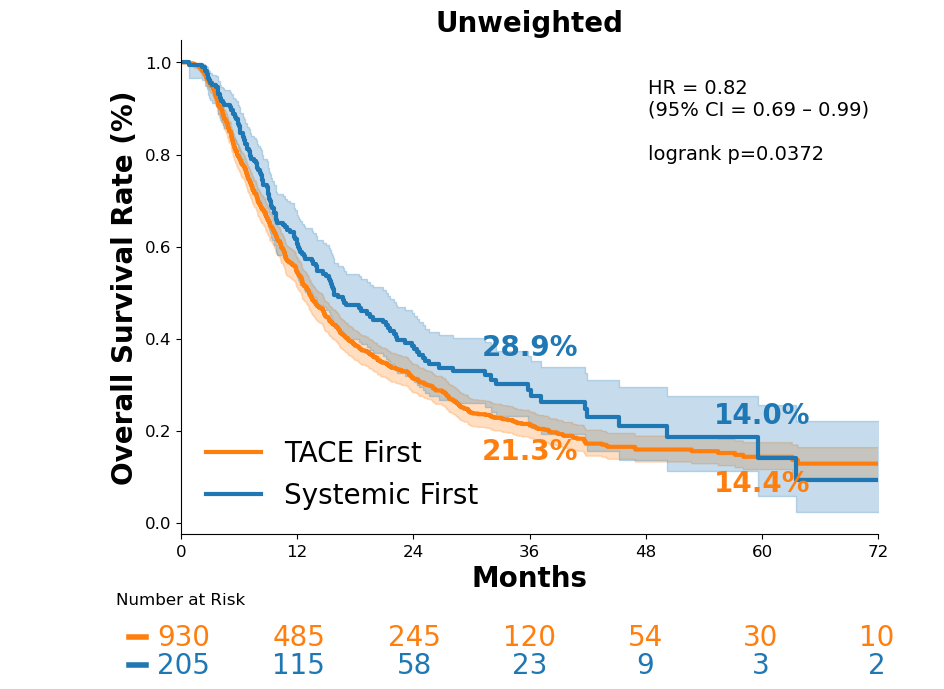

In [50]:
survival_analysis(df, np.arange(0, 73, 12))#, file_name='tace_sys_unweighted')  # IPTW-weighted analysis

<lifelines.CoxPHFitter: fitted with 797 total observations, 220 right-censored observations>
             duration col = 'time'
                event col = 'event'
                   strata = subclass
      baseline estimation = breslow
   number of observations = 797
number of events observed = 577
   partial log-likelihood = -550.83
         time fit was run = 2026-01-11 16:54:47 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.17      0.84      0.12           -0.40            0.05                0.67                1.06

                cmp to     z    p  -log2(p)
covariate                                  
sequence_group    0.00 -1.49 0.14      2.88
---
Concordance = 0.52
Partial AIC = 1103.65
log-likelihood ratio test = 2.27 on 1 df
-log2(p) of ll-ratio test = 2.93


Time: 36 months
TACE First: 19.6% (16.0% – 23.4%)
Systemic First: 28.4% (21.3% – 35.9%)

Time: 60 months
TACE First: 14.0% (10.2% – 18.5%)
Systemic First: 14.4% (6.0% – 26.2%)


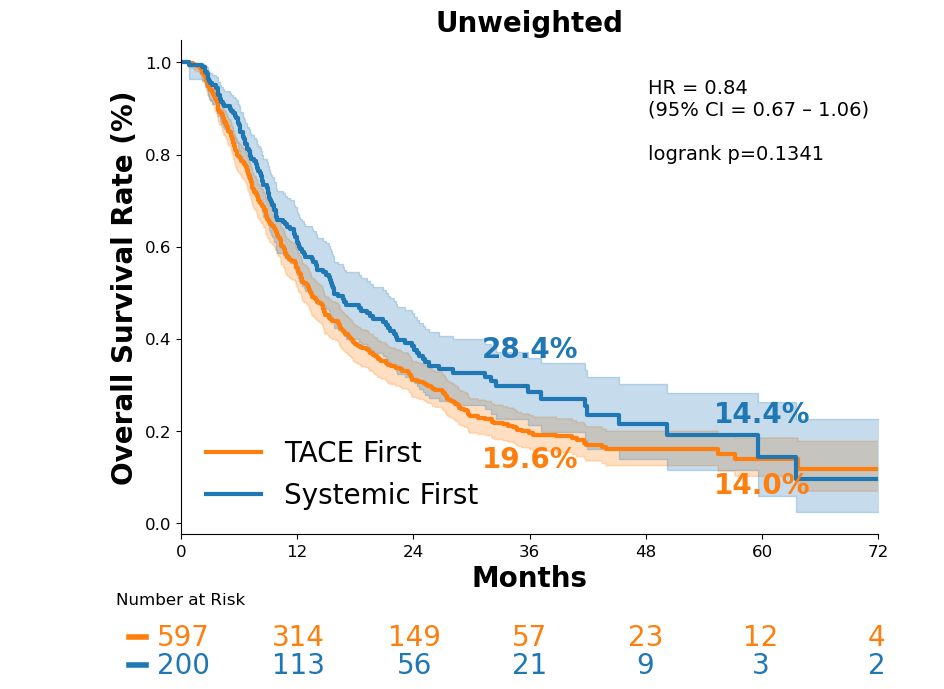

In [51]:
df_matched = pd.read_csv('matched_tace_sys.csv')
survival_analysis(df_matched, np.arange(0, 73, 12), strata = 'subclass')#, file_name='tace_sys_unweighted')  # IPTW-weighted analysis

In [52]:
cph = CoxPHFitter()
cph.fit(df_matched[['time', 'event', 'sequence_group', 'subclass']], duration_col='time', event_col='event', strata='subclass')
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 797 total observations, 220 right-censored observations>
             duration col = 'time'
                event col = 'event'
                   strata = subclass
      baseline estimation = breslow
   number of observations = 797
number of events observed = 577
   partial log-likelihood = -550.83
         time fit was run = 2026-01-11 16:54:48 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.17      0.84      0.12           -0.40            0.05                0.67                1.06

                cmp to     z    p  -log2(p)
covariate                                  
sequence_group    0.00 -1.49 0.14      2.88
---
Concordance = 0.52
Partial AIC = 1103.65
log-likelihood ratio test = 2.27 on 1 df
-log2(p) of ll-ratio test = 2.93

## IPTW

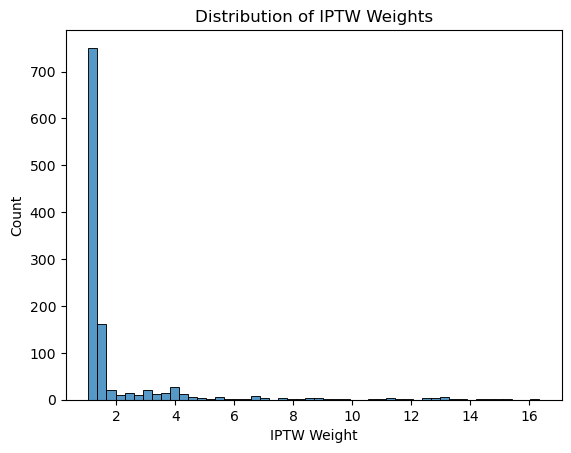

In [53]:
df = perform_iptw(df, covariates)

sns.histplot(df['iptw_weight'], bins=50)
plt.title("Distribution of IPTW Weights")
plt.xlabel("IPTW Weight")
plt.ylabel("Count")
plt.show()

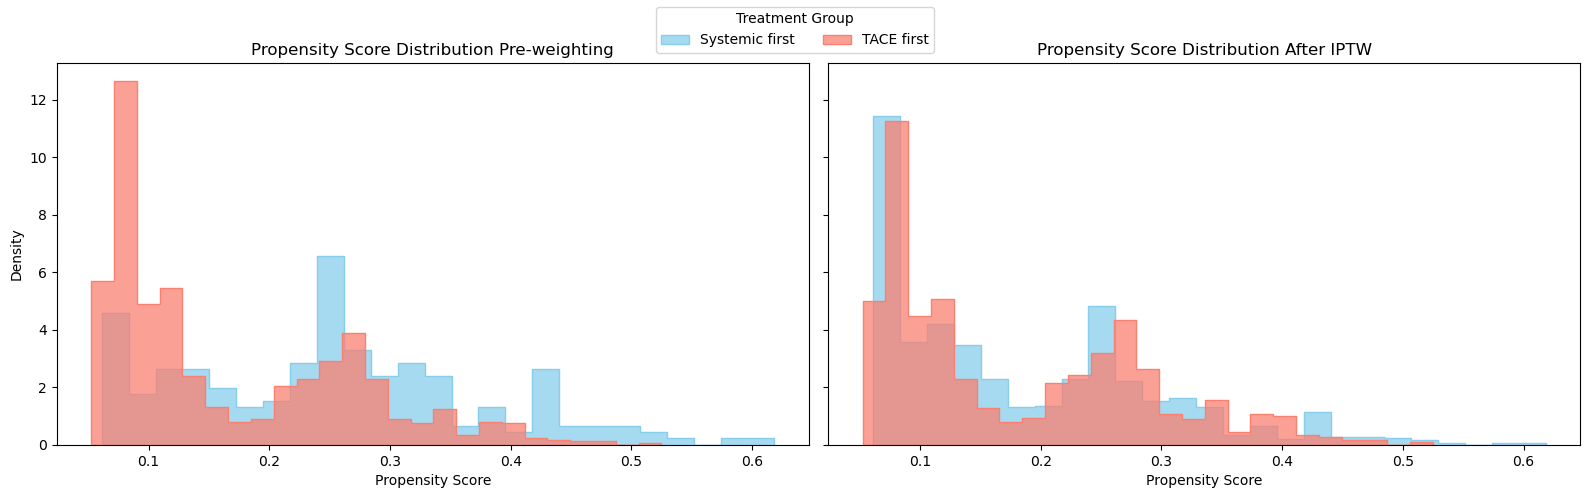

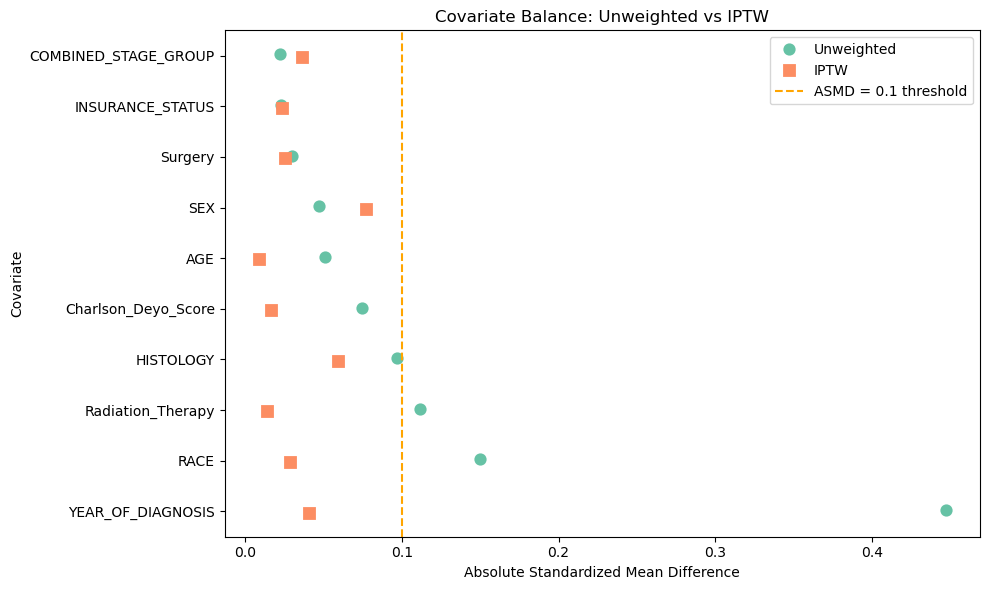

In [54]:
asmd_df = generate_iptw_plots(df, ['TACE first', 'Systemic first'])#, file_name='tace_sys')  # IPTW-weighted analysis

## IPTW Weighted Survival Analysis

<lifelines.CoxPHFitter: fitted with 2246.04 total observations, 616.269 right-censored observations>
             duration col = 'time'
                event col = 'event'
              weights col = 'iptw_weight'
      baseline estimation = breslow
   number of observations = 2246.04
number of events observed = 1629.77
   partial log-likelihood = -11453.68
         time fit was run = 2026-01-11 16:54:49 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
sequence_group -0.21      0.81      0.05           -0.30           -0.11                0.74                0.90

                cmp to     z      p  -log2(p)
covariate                                    
sequence_group    0.00 -4.16 <0.005     14.95
---
Concordance = 0.52
Partial AIC = 22909.35
log-likelihood ratio test = 17.36 on 1 df
-log2(p) of ll-ratio test = 14.98


Time: 36 months
TACE First: 21.3% (18.6% – 23.9%)
Systemic First: 30.3% (27.0% – 32.9%)

Time: 60 months
TACE First: 14.4% (11.8% – 17.2%)
Systemic First: 18.3% (14.9% – 21.9%)


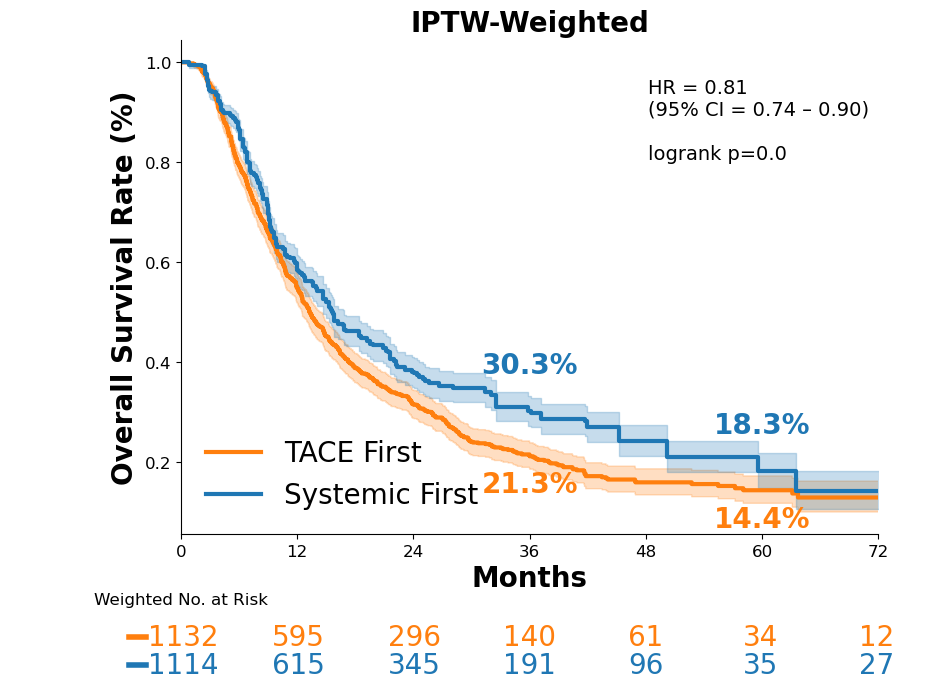

In [55]:
survival_analysis(df, np.arange(0, 73, 12), weight_col='iptw_weight')#, file_name='tace_sys_iptw') 

## TACE first vs. Systemic first in different combinations of stages

In [56]:
combinations = [
    [1], [2], [3], [4],
    [1,2], [2,3], [3,4],
    [1,2,3], [2,3,4]
]

# DataFrame to store the HR and p-values for each combination
df_results = pd.DataFrame(columns=['Stage Combination', 'HR', 'CI Low', 'CI High', 'p-value', 'n'])

for combo in combinations:
    combo_name = " + ".join(map(str, combo))
    
    df_combo = pd.read_csv('analysis_ready.csv')
    df_combo = df_combo[df_combo['sequence_group'].isin([0, 1])]
    df_combo = df_combo[df_combo['COMBINED_STAGE_GROUP'].isin(combo)]
    if len(combo) == 1:
        covariates_1 = [cov for cov in covariates if cov != 'COMBINED_STAGE_GROUP']
        df_combo = perform_iptw(df_combo, covariates=covariates_1)
    else:
        df_combo = perform_iptw(df_combo)
    
    cph = CoxPHFitter()
    cph.fit(df_combo[['time', 'event', 'sequence_group', 'iptw_weight']], duration_col='time', event_col='event', weights_col='iptw_weight')
    
    summary_df = cph.summary
    p_val = summary_df.loc['sequence_group', 'p'].round(4)
    hr = summary_df.loc['sequence_group', 'exp(coef)']
    ci_low = summary_df.loc['sequence_group', 'exp(coef) lower 95%']
    ci_high = summary_df.loc['sequence_group', 'exp(coef) upper 95%']
    
    # Create a new row as a DataFrame
    new_row = pd.DataFrame({
        'Stage Combination': [combo_name],
        'HR': [hr],
        'CI Low': [ci_low],
        'CI High': [ci_high],
        'p-value': [p_val],
        'n': [df_combo.shape[0]]
    })
    
    # Use pd.concat to add the new row
    df_results = pd.concat([df_results, new_row], ignore_index=True)

/var/folders/4r/chd7cdjn77j6krd2g7fstr3h0000gn/T/ipykernel_56571/1874346471.py:42: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_results = pd.concat([df_results, new_row], ignore_index=True)


In [57]:
df_results

,Stage Combination,HR,CI Low,CI High,p-value,n
0,1,0.711177,0.501795,1.007927,0.0554,136
1,2,0.955567,0.749335,1.218557,0.7141,225
2,3,0.782908,0.679608,0.901910,0.0007,571
3,4,0.798313,0.695124,0.916820,0.0014,564
4,1 + 2,0.947095,0.780069,1.149883,0.5829,361
5,2 + 3,0.858711,0.760535,0.969560,0.0139,796
6,3 + 4,0.813090,0.737590,0.896319,0.0000,1135
7,1 + 2 + 3,0.865054,0.772251,0.969009,0.0123,932
8,2 + 3 + 4,0.857621,0.783950,0.938216,0.0008,1360


## Spacing analysis - Systemic first

In [58]:
df_sys = df[(df['sequence_group'].isin([1,2])) & df['COMBINED_STAGE_GROUP'].isin([3,4])].copy()
df_sys = df_sys[df_sys['DX_IMMUNO_STARTED_DAYS'] <= df_sys['DX_CHEMO_STARTED_DAYS']]



In [59]:
df_sys.shape

(205, 359)

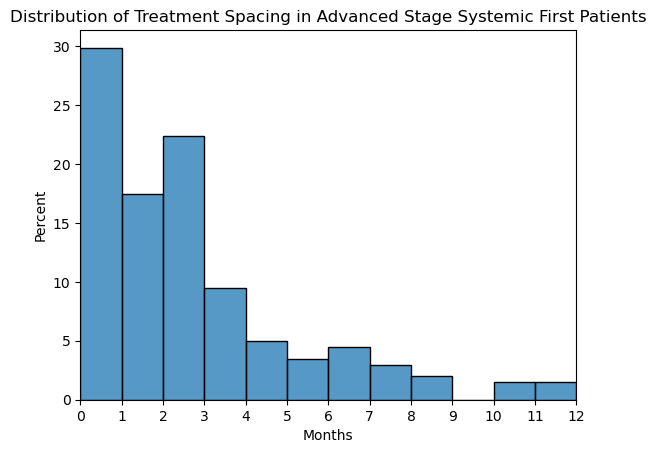

In [60]:
df_sys['treatment_spacing'] =  abs(df_sys['DX_CHEMO_STARTED_DAYS'] - df_sys['DX_IMMUNO_STARTED_DAYS'])
#df_sys = df_sys[df_sys['treatment_spacing'] <= 90] 

df_sys['treatment_spacing_months'] = df_sys['treatment_spacing'] / 30.44  # Convert to months

bin_edges = np.linspace(0, 12, 13)  # Create 12 bins from 0 to 12 months
sns.histplot(df_sys['treatment_spacing_months'], bins=bin_edges, stat="percent")
plt.title("Distribution of Treatment Spacing in Advanced Stage Systemic First Patients")
plt.xlabel("Months")
plt.xlim(0, 12)
plt.xticks(bin_edges)
# plt.savefig("treatment_spacing_distribution.pdf", format='pdf', bbox_inches='tight')
plt.show()


In [61]:
def plot_spacing(df, spacing_col, title, llp, file_name = None):
    kmf = KaplanMeierFitter()

    plt.figure(figsize=(10, 6))

    muted_colors = ["#0008ff", "#ff0000", "#000000", "#008E28"]

    for i, group in enumerate(df[spacing_col].unique()):
        mask = df[spacing_col] == group
        kmf.fit(
            durations=df.loc[mask, 'time'],
            event_observed=df.loc[mask, 'event'],
            label=f"{group} (n={mask.sum()})"
        )
        kmf.plot(ci_show=False, linewidth=2, color=muted_colors[i % len(muted_colors)])


    plt.text(0.15, 0.1, f"Log-likelihood p={llp:.4f}", fontsize=14, transform=plt.gca().transAxes, ha='center', va='center', bbox=dict(facecolor='white', alpha=0.5, edgecolor='black'))
    plt.title(title)
    plt.ylabel("Overall Survival Probability")
    plt.xlabel("Time (months)")
    plt.xlim(0, 72)
    plt.xticks(np.arange(0, 73, 12))
    plt.grid(False)
    plt.legend()
    plt.tight_layout()
    if file_name:
        plt.savefig(f"{file_name}.pdf", format='pdf', bbox_inches='tight')
    plt.show()

### 7,14,28

In [62]:
df_sys['spacing_week'] = pd.cut(
    df_sys['treatment_spacing'],
    bins=[-1, 7, 14, 28, np.inf],
    labels=['≤7 days', '8–14 days', '15–28 days', '>28 days']
)

# df_sys['spacing_week'] = pd.Categorical(
#     df_sys['spacing_week'], 
#     categories=['≤7 days', '15–28 days', '8–14 days', '>28 days'],
#     ordered=True
# )

In [63]:
cph_7 = CoxPHFitter()
df_dummies1 = pd.get_dummies(df_sys, columns=['spacing_week'], drop_first=True)
# cph_7.fit(
#     df_dummies1[['time', 'event'] + list(df_dummies1.columns[df_dummies1.columns.str.startswith('spacing_week_')])], 
#     duration_col='time', 
#     event_col='event')
# cph_7.print_summary()

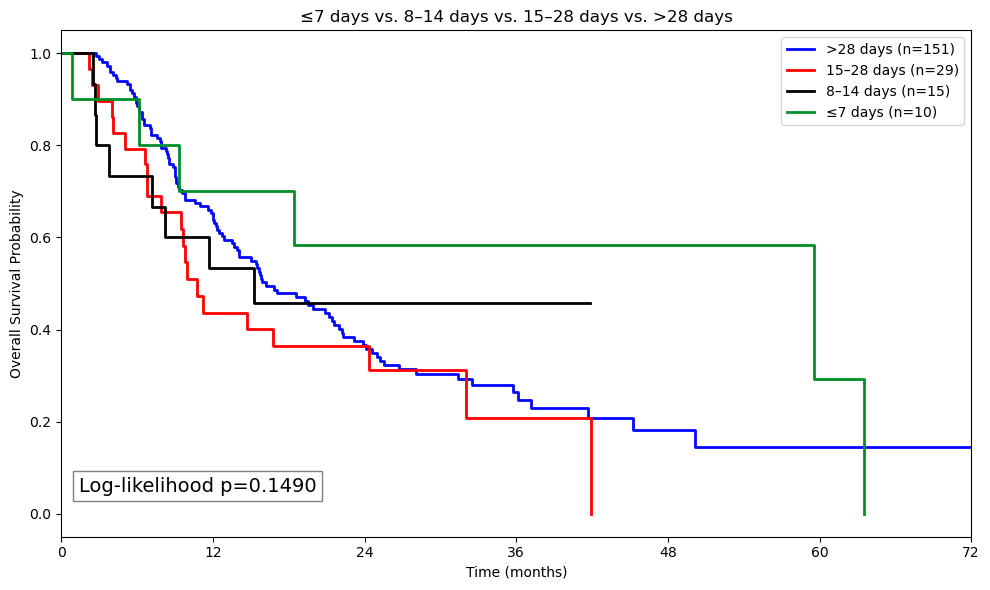

In [64]:
plot_spacing(df_sys, 'spacing_week', "≤7 days vs. 8–14 days vs. 15–28 days vs. >28 days", 0.149)

### 30, 90

In [65]:
df_sys['spacing_3090'] = pd.cut(
    df_sys['treatment_spacing'],
    bins=[-1, 30, 90, np.inf],
    labels=['≤30 days', '31–90 days', '>90 days']
)

df_sys['spacing_3090'] = pd.Categorical(
    df_sys['spacing_3090'],
    categories=['>90 days', '31–90 days', '≤30 days'],  # Reorder categories
    ordered=True
)

In [66]:
# cph_3090 = CoxPHFitter()
# df_dummies2 = pd.get_dummies(df_sys, columns=['spacing_3090'], drop_first=True)
# cph_3090.fit(
#     df_dummies2[['time', 'event'] + list(df_dummies2.columns[df_dummies2.columns.str.startswith('spacing_3090_')])], 
#     duration_col='time', 
#     event_col='event')
# cph_3090.print_summary()


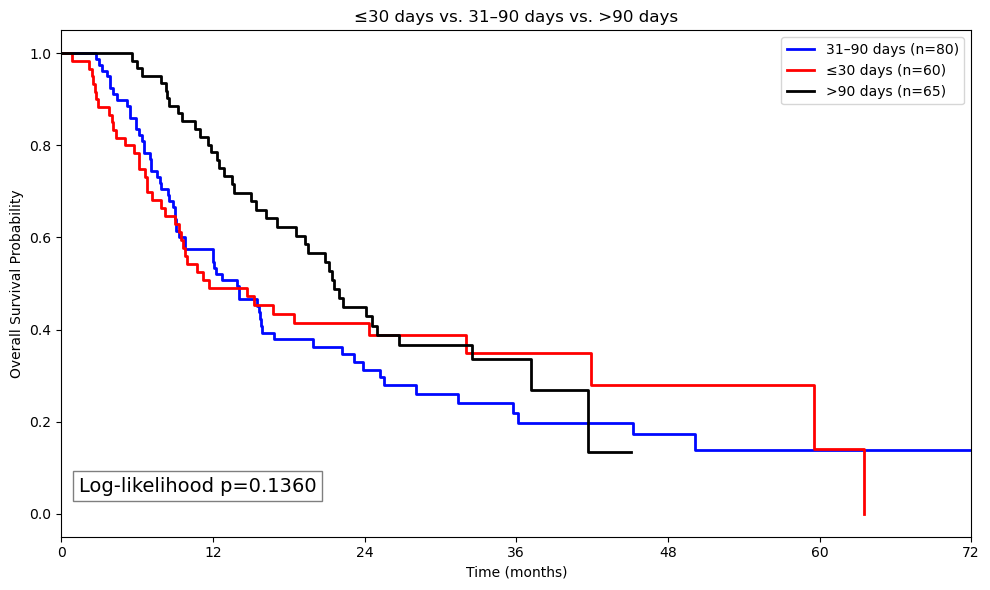

In [67]:
plot_spacing(df_sys, 'spacing_3090', "≤30 days vs. 31–90 days vs. >90 days", 0.136)

### Quartiles

In [68]:
df_sys['spacing_quartile'] = pd.qcut(df_sys['treatment_spacing'], q=4, labels=['≤22 days', '23–62 days', '63–105 days', '>105 days'])
quartile_cutoffs = df_sys['treatment_spacing'].quantile([0.25, 0.5, 0.75]).values
print("Quartile cutoffs:", quartile_cutoffs)

df_sys['spacing_quartile'] = pd.Categorical(
    df_sys['spacing_quartile'],
    categories=['>105 days', '≤22 days', '23–62 days', '63–105 days'],  # Reorder categories to match quartiles
    ordered=True
)

df_dummies3 = pd.get_dummies(df_sys, columns=['spacing_quartile'], drop_first=True)
cph_q = CoxPHFitter()
cph_q.fit(
    df_dummies3[['time', 'event'] + list(df_dummies3.columns[df_dummies3.columns.str.startswith('spacing_quartile_')])],
    duration_col='time',
    event_col='event'
)
cph_q.print_summary()

Quartile cutoffs: [ 28.  63. 110.]


<lifelines.CoxPHFitter: fitted with 205 total observations, 69 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 205
number of events observed = 136
   partial log-likelihood = -627.07
         time fit was run = 2026-01-11 16:54:51 UTC

---
                              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                     
spacing_quartile_≤22 days     0.22      1.24      0.25           -0.27            0.70                0.77                2.01
spacing_quartile_23–62 days   0.37      1.45      0.25           -0.11            0.85                0.89                2.35
spacing_quartile_63–105 days  0.32      1.38      0.25           -0.17            0.81                0.85                2.25

                              cmp to    z    p  -log2(p)
covariate                                               
spacing_quartile_≤22 days       0.00 0.88 0.38      1.39
spacing_quartile_23–62 days     0.00 1.50 0.13      2.91
spacing_quartile_63–105 days    0.00 1.29 0.20      2.35
---
Concordance = 0.57
Partial AIC = 1260.14
log-likelihood ratio test = 2.72 on 3 df
-log2(p) of ll-ratio test = 1.20

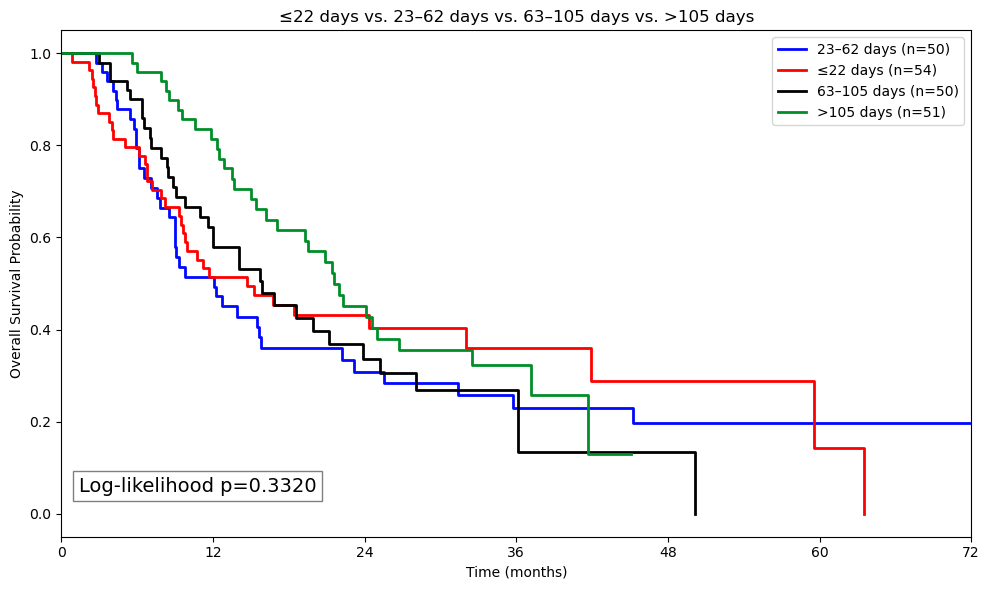

In [69]:
plot_spacing(df_sys, 'spacing_quartile', '≤22 days vs. 23–62 days vs. 63–105 days vs. >105 days', 0.332)

### Log rank test for best cut point

In [70]:

best_cut = None
best_stat = 0

#for cut in np.arange(7, df_sys['treatment_spacing'].max(),7):
for cut in range(1, int(df_sys['treatment_spacing'].max())):
    mask_low = df_sys['treatment_spacing'] <= cut
    mask_high = df_sys['treatment_spacing'] > cut
    if mask_low.sum() < (df_sys.shape[0]*0.25) or mask_high.sum() < (df_sys.shape[0]*0.25):
        continue  # avoid tiny groups
    results = logrank_test(
        df_sys.loc[mask_low, 'time'],
        df_sys.loc[mask_high, 'time'],
        event_observed_A=df_sys.loc[mask_low, 'event'],
        event_observed_B=df_sys.loc[mask_high, 'event']
    )
    if results.test_statistic > best_stat:
        best_stat = results.test_statistic
        best_cut = cut

print("Optimal cutpoint (days):", best_cut, "– log‐rank stat:", best_stat)

best_cut = 14

Optimal cutpoint (days): 88 – log‐rank stat: 4.388339942215598


In [71]:
df_sys['spacing_binary'] = (df_sys['treatment_spacing'] > best_cut).astype(int)
cph_cut = CoxPHFitter()
# cph_cut.fit(
#     df_sys[['time','event','spacing_binary']],
#     duration_col='time',
#     event_col='event'
# )
# cph_cut.print_summary()
# cph_cut.summary.loc['spacing_binary', 'p'].round(4)

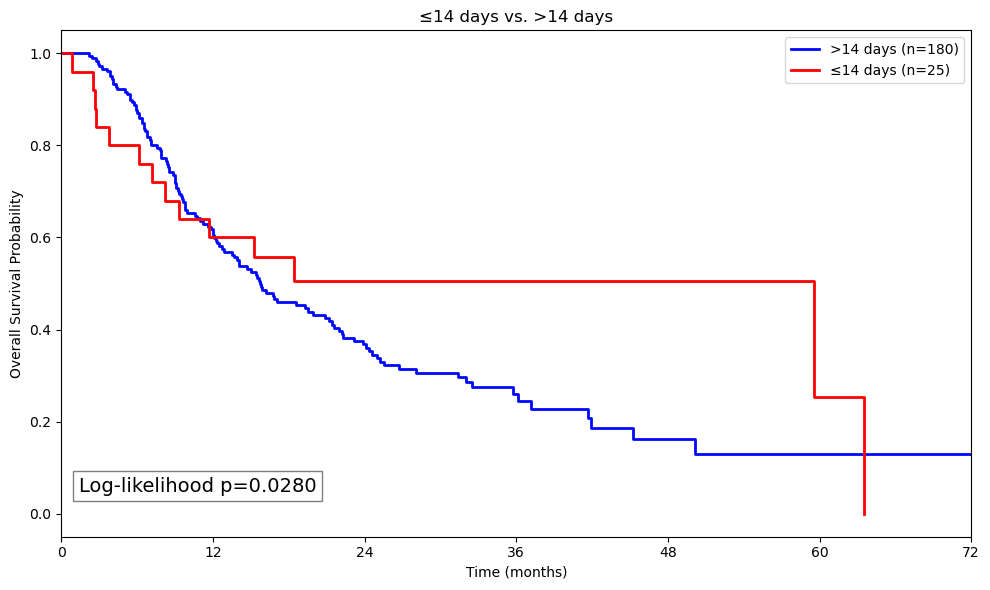

In [72]:
df_sys['spacing_binary'] = df_sys['spacing_binary'].map({0: '≤' + str(best_cut) + ' days', 1: '>' + str(best_cut) + ' days'})
plot_spacing(df_sys, 'spacing_binary', '≤14 days vs. >14 days', 0.028)

### Rrestricted Cubic Spline

In [73]:
from sklearn.preprocessing import SplineTransformer

median_spacing = df_sys['treatment_spacing'].median()
spacing_centered = df_sys['treatment_spacing'] - median_spacing

quantiles = np.percentile(spacing_centered, [20, 40, 60, 80])
knots = quantiles.reshape(-1, 1)

spline = SplineTransformer(
    degree=3,
    knots=knots,            
    extrapolation="linear", 
    include_bias=False      
)
X_spline = spline.fit_transform(spacing_centered.values.reshape(-1, 1))

basis_df = pd.DataFrame(
    X_spline, 
    columns=[f"spline_{i+1}" for i in range(X_spline.shape[1])]
)

for colname in basis_df.columns:
    df_sys[colname] = basis_df[colname].values

cph_rcs = CoxPHFitter()

cph_rcs.fit(
    df_sys[['time', 'event'] + basis_df.columns.tolist()],
    duration_col='time', 
    event_col='event'
)
cph_rcs.print_summary()

x_min, x_max = spacing_centered.min(), spacing_centered.max()
xs = np.linspace(x_min, x_max, 200)
xs_actual = xs + median_spacing  
X_grid = spline.transform(xs.reshape(-1, 1))  

B_ref = spline.transform([[0]])

# Extract the estimated beta coefficients for the spline columns:
beta_spline = cph_rcs.params_.loc[basis_df.columns].values

# Compute f(xs): a length-200 array
f_xs = X_grid.dot(beta_spline)

# Compute f(x_ref): a single number
f_xref = B_ref.dot(beta_spline).item()

# Now the “log–HR” relative to x_ref at each grid point:
log_hr = f_xs - f_xref

# And the HR curve:
hr_curve = np.exp(log_hr)

<lifelines.CoxPHFitter: fitted with 205 total observations, 69 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 205
number of events observed = 136
   partial log-likelihood = -624.79
         time fit was run = 2026-01-11 16:54:52 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
spline_1  -3.65      0.03      2.28           -8.12            0.81                0.00                2.26
spline_2   0.25      1.28      0.80           -1.33            1.82                0.26                6.18
spline_3  -1.05      0.35      1.24           -3.47            1.38                0.03                3.97
spline_4  -0.31      0.73      0.41           -1.11            0.49                0.33                1.63
spline_5  -1.64      0.19      1.50           -4.58            1.30                0.01                3.66

           cmp to     z    p  -log2(p)
covariate                             
spline_1     0.00 -1.60 0.11      3.20
spline_2     0.00  0.31 0.76      0.40
spline_3     0.00 -0.85 0.40      1.33
spline_4     0.00 -0.76 0.44      1.17
spline_5     0.00 -1.10 0.27      1.87
---
Concordance = 0.58
Partial AIC = 1259.58
log-likelihood ratio test = 7.28 on 5 df
-log2(p) of ll-ratio test = 2.32

In [74]:
#Bootstrapping for confidence intervals
n_boot = 200

hr_boot = np.zeros((n_boot, len(xs_actual)))  

for i in range(n_boot):
    boot_df = df_sys.sample(frac=1, replace=True).copy()

    median_b = boot_df['treatment_spacing'].median()

    boot_df['spacing_centered_b'] = boot_df['treatment_spacing'] - median_b

    quantile_positions = [5, 35, 65, 95]
    knot_values_b = np.percentile(
        boot_df['spacing_centered_b'], quantile_positions
    ).reshape(-1,1)

    sb_b = SplineTransformer(
        degree=3,
        knots=knot_values_b,
        extrapolation="linear",
        include_bias=False
    )

    Xb = sb_b.fit_transform(boot_df[['spacing_centered_b']].values)
    spline_cols_b = [f"spline_b_{j+1}" for j in range(Xb.shape[1])]
    for j, col in enumerate(spline_cols_b):
        boot_df[col] = Xb[:, j]

    cph_b = CoxPHFitter(penalizer=0.01)
    cph_b.fit(
        boot_df[['time', 'event'] + spline_cols_b],
        duration_col='time',
        event_col='event'
    )
    beta_b = cph_b.params_.loc[spline_cols_b].values

    xs_b_centered = xs_actual - median_b

    Xg_b = sb_b.transform(xs_b_centered.reshape(-1, 1))

    fx_b   = Xg_b.dot(beta_b)                        
    bref_b = sb_b.transform([[0]]).ravel()           
    fref_b = bref_b.dot(beta_b)

    hr_boot[i, :] = np.exp(fx_b - fref_b)

hr_lower = np.percentile(hr_boot, 2.5, axis=0)
hr_upper = np.percentile(hr_boot, 97.5, axis=0)
hr_median = np.percentile(hr_boot, 50, axis=0)


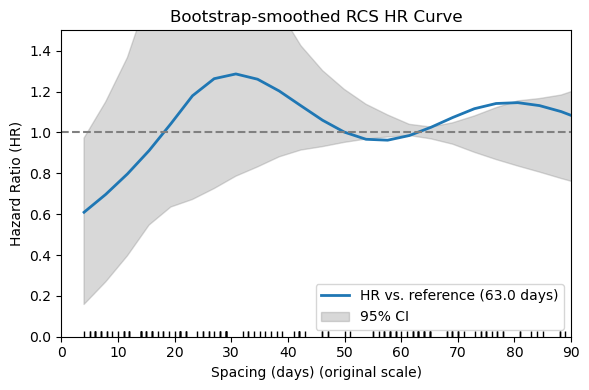

In [75]:
plt.figure(figsize=(6,4))
plt.plot(
    xs_actual,                   
    hr_curve,
    lw=2,
    label=f"HR vs. reference ({median_spacing:.1f} days)"
)
plt.fill_between(
    xs_actual, 
    hr_lower, 
    hr_upper, 
    color='gray', 
    alpha=0.3, 
    label='95% CI'
)
sns.rugplot(df_sys['treatment_spacing'], height=0.02, color="black")
plt.ylim(0, 1.5)
plt.xlim(0,90)
plt.axhline(1.0, color='gray', linestyle='--')
plt.xlabel("Spacing (days) (original scale)")
plt.ylabel("Hazard Ratio (HR)")
plt.title("Bootstrap‐smoothed RCS HR Curve")
plt.legend()
plt.tight_layout()
plt.show()

## Spacing Analysis - TACE first

<Axes: xlabel='treatment_spacing', ylabel='Count'>

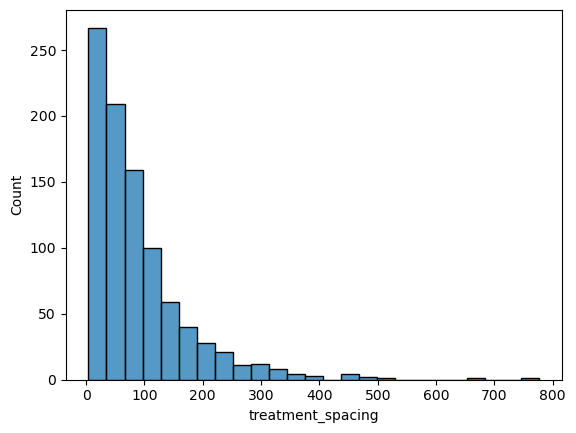

In [76]:
df_tace = df[df['sequence_group'] == 0].copy()
df_tace['treatment_spacing'] =  abs(df_tace['DX_CHEMO_STARTED_DAYS'] - df_tace['DX_IMMUNO_STARTED_DAYS'])
sns.histplot(df_tace['treatment_spacing'], bins=25)

### 7,14,28

In [77]:
df_tace['spacing_week'] = pd.cut(
    df_tace['treatment_spacing'],
    bins=[-1, 7, 14, 28, np.inf],
    labels=['≤7 days', '8–14 days', '15–28 days', '>28 days']
)

cph_7 = CoxPHFitter()
df_dummies1 = pd.get_dummies(df_tace, columns=['spacing_week'], drop_first=True)
# cph_7.fit(
#     df_dummies1[['time', 'event'] + list(df_dummies1.columns[df_dummies1.columns.str.startswith('spacing_week_')])], 
#     duration_col='time', 
#     event_col='event')
# cph_7.print_summary()
# plot_spacing(df_tace, 'spacing_week', "≤7 days vs. 8–14 days vs. 15–28 days vs. >28 days")

### 30,90

In [78]:
df_tace['spacing_3090'] = pd.cut(
    df_tace['treatment_spacing'],
    bins=[-1, 30, 90, np.inf],
    labels=['≤30 days', '31–90 days', '>90 days']
)

df_tace['spacing_3090'] = pd.Categorical(
    df_tace['spacing_3090'],
    categories=['>90 days', '31–90 days', '≤30 days'],  # Reorder categories
    ordered=True
)

cph_3090 = CoxPHFitter()
df_dummies2 = pd.get_dummies(df_tace, columns=['spacing_3090'], drop_first=True)
cph_3090.fit(
    df_dummies2[['time', 'event'] + list(df_dummies2.columns[df_dummies2.columns.str.startswith('spacing_3090_')])], 
    duration_col='time', 
    event_col='event')
cph_3090.print_summary()

# plot_spacing(df_tace, 'spacing_3090', "≤30 days vs. 31–90 days vs. >90 days")

<lifelines.CoxPHFitter: fitted with 930 total observations, 216 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 930
number of events observed = 714
   partial log-likelihood = -4375.70
         time fit was run = 2026-01-11 16:54:55 UTC

---
                         coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                
spacing_3090_31–90 days  0.30      1.34      0.09            0.13            0.47                1.13                1.59
spacing_3090_≤30 days    0.26      1.30      0.10            0.07            0.45                1.07                1.57

                         cmp to    z      p  -log2(p)
covariate                                            
spacing_3090_31–90 days    0.00 3.40 <0.005     10.55
spacing_3090_≤30 days      0.00 2.68   0.01      7.07
---
Concordance = 0.56
Partial AIC = 8755.39
log-likelihood ratio test = 13.37 on 2 df
-log2(p) of ll-ratio test = 9.65

### Quartiles

In [79]:
df_tace['spacing_quartile'] = pd.qcut(df_tace['treatment_spacing'], q=4, labels=['≤31 days', '32–67 days', '68–125 days', '>125 days'])
quartile_cutoffs = df_tace['treatment_spacing'].quantile([0.25, 0.5, 0.75]).values
print("Quartile cutoffs:", quartile_cutoffs)

df_tace['spacing_quartile'] = pd.Categorical(
    df_tace['spacing_quartile'],
    categories=['>125 days', '≤31 days', '32–67 days', '68–125 days'],  # Reorder categories to match quartiles
    ordered=True
)

df_dummies3 = pd.get_dummies(df_tace, columns=['spacing_quartile'], drop_first=True)
cph_q = CoxPHFitter()
cph_q.fit(
    df_dummies3[['time', 'event'] + list(df_dummies3.columns[df_dummies3.columns.str.startswith('spacing_quartile_')])],
    duration_col='time',
    event_col='event'
)
cph_q.print_summary()

# plot_spacing(df_tace, 'spacing_quartile', '≤31 days vs. 32–67 days vs. 68–125 days vs. >125 days')

Quartile cutoffs: [ 30.    63.   113.75]


<lifelines.CoxPHFitter: fitted with 930 total observations, 216 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 930
number of events observed = 714
   partial log-likelihood = -4372.03
         time fit was run = 2026-01-11 16:54:55 UTC

---
                              coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                     
spacing_quartile_≤31 days     0.34      1.40      0.11            0.13            0.55                1.14                1.73
spacing_quartile_32–67 days   0.46      1.59      0.11            0.25            0.67                1.29                1.95
spacing_quartile_68–125 days  0.25      1.28      0.11            0.04            0.46                1.04                1.58

                              cmp to    z      p  -log2(p)
covariate                                                 
spacing_quartile_≤31 days       0.00 3.18 <0.005      9.42
spacing_quartile_32–67 days     0.00 4.34 <0.005     16.12
spacing_quartile_68–125 days    0.00 2.34   0.02      5.70
---
Concordance = 0.59
Partial AIC = 8750.05
log-likelihood ratio test = 20.71 on 3 df
-log2(p) of ll-ratio test = 13.02

### Log rank for best cut

In [80]:
best_cut = None
best_stat = 0

for cut in range(1, int(df_tace['treatment_spacing'].max())):
    mask_low = df_tace['treatment_spacing'] <= cut
    mask_high = df_tace['treatment_spacing'] > cut
    if mask_low.sum() < (df_tace.shape[0]*0.25) or mask_high.sum() < (df_tace.shape[0]*0.25):
         continue  # avoid tiny groups
    results = logrank_test(
        df_tace.loc[mask_low, 'time'],
        df_tace.loc[mask_high, 'time'],
        event_observed_A=df_tace.loc[mask_low, 'event'],
        event_observed_B=df_tace.loc[mask_high, 'event']
    )
    if results.test_statistic > best_stat:
        best_stat = results.test_statistic
        best_cut = cut

print("Optimal cutpoint (days):", best_cut, "– log‐rank stat:", best_stat)

df_tace['spacing_binary'] = (df_tace['treatment_spacing'] > best_cut).astype(int)
cph_cut = CoxPHFitter()
cph_cut.fit(
    df_tace[['time','event','spacing_binary']],
    duration_col='time',
    event_col='event'
)
cph_cut.print_summary()
cph_cut.summary.loc['spacing_binary', 'p'].round(4)

# plot_spacing(df_tace, 'spacing_binary', '≤105 days vs. >105 days')

Optimal cutpoint (days): 97 – log‐rank stat: 18.55966366901092


<lifelines.CoxPHFitter: fitted with 930 total observations, 216 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 930
number of events observed = 714
   partial log-likelihood = -4372.80
         time fit was run = 2026-01-11 16:54:56 UTC

---
                coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                       
spacing_binary -0.35      0.70      0.08           -0.51           -0.19                0.60                0.83

                cmp to     z      p  -log2(p)
covariate                                    
spacing_binary    0.00 -4.29 <0.005     15.75
---
Concordance = 0.57
Partial AIC = 8747.60
log-likelihood ratio test = 19.16 on 1 df
-log2(p) of ll-ratio test = 16.35

np.float64(0.0)

### TACE RCS

<lifelines.CoxPHFitter: fitted with 930 total observations, 216 right-censored observations>
             duration col = 'time'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 930
number of events observed = 714
   partial log-likelihood = -4369.96
         time fit was run = 2026-01-11 16:54:56 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
spline_1   1.82      6.20      1.35           -0.83            4.47                0.44               87.77
spline_2   0.38      1.46      0.65           -0.90            1.65                0.41                5.22
spline_3   0.73      2.08      0.78           -0.80            2.26                0.45                9.57
spline_4   0.31      1.36      0.53           -0.73            1.35                0.48                3.85
spline_5   0.10      1.11      1.08           -2.01            2.22                0.13                9.19

           cmp to    z    p  -log2(p)
covariate                            
spline_1     0.00 1.35 0.18      2.49
spline_2     0.00 0.58 0.56      0.82
spline_3     0.00 0.94 0.35      1.52
spline_4     0.00 0.59 0.56      0.84
spline_5     0.00 0.10 0.92      0.12
---
Concordance = 0.59
Partial AIC = 8749.93
log-likelihood ratio test = 24.84 on 5 df
-log2(p) of ll-ratio test = 12.71

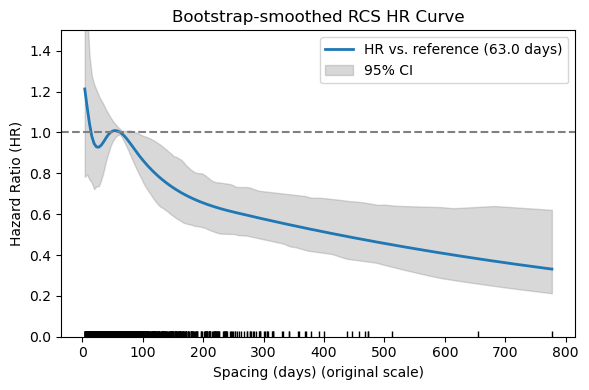

In [81]:
median_spacing = df_tace['treatment_spacing'].median()
spacing_centered = df_tace['treatment_spacing'] - median_spacing

quantiles = np.percentile(spacing_centered, [5, 35, 65, 95])
knots = quantiles.reshape(-1, 1)

spline = SplineTransformer(
    degree=3,
    knots=knots,            
    extrapolation="linear", 
    include_bias=False      
)
X_spline = spline.fit_transform(spacing_centered.values.reshape(-1, 1))

basis_df = pd.DataFrame(
    X_spline, 
    columns=[f"spline_{i+1}" for i in range(X_spline.shape[1])]
)

for colname in basis_df.columns:
    df_tace[colname] = basis_df[colname].values

cph_rcs = CoxPHFitter()

cph_rcs.fit(
    df_tace[['time', 'event'] + basis_df.columns.tolist()],
    duration_col='time', 
    event_col='event'
)
cph_rcs.print_summary()

x_min, x_max = spacing_centered.min(), spacing_centered.max()
xs = np.linspace(x_min, x_max, 200)
xs_actual = xs + median_spacing  
X_grid = spline.transform(xs.reshape(-1, 1))  

B_ref = spline.transform([[0]])

# Extract the estimated beta coefficients for the spline columns:
beta_spline = cph_rcs.params_.loc[basis_df.columns].values

# Compute f(xs): a length-200 array
f_xs = X_grid.dot(beta_spline)

# Compute f(x_ref): a single number
f_xref = B_ref.dot(beta_spline).item()

# Now the “log–HR” relative to x_ref at each grid point:
log_hr = f_xs - f_xref

# And the HR curve:
hr_curve = np.exp(log_hr)

#Bootstrapping for confidence intervals
n_boot = 200

hr_boot = np.zeros((n_boot, len(xs_actual)))  

for i in range(n_boot):
    boot_df = df_tace.sample(frac=1, replace=True).copy()

    median_b = boot_df['treatment_spacing'].median()

    boot_df['spacing_centered_b'] = boot_df['treatment_spacing'] - median_b

    quantile_positions = [5, 35, 65, 95]
    knot_values_b = np.percentile(
        boot_df['spacing_centered_b'], quantile_positions
    ).reshape(-1,1)

    sb_b = SplineTransformer(
        degree=3,
        knots=knot_values_b,
        extrapolation="linear",
        include_bias=False
    )

    Xb = sb_b.fit_transform(boot_df[['spacing_centered_b']].values)
    spline_cols_b = [f"spline_b_{j+1}" for j in range(Xb.shape[1])]
    for j, col in enumerate(spline_cols_b):
        boot_df[col] = Xb[:, j]

    cph_b = CoxPHFitter(penalizer=0.01)
    cph_b.fit(
        boot_df[['time', 'event'] + spline_cols_b],
        duration_col='time',
        event_col='event'
    )
    beta_b = cph_b.params_.loc[spline_cols_b].values

    xs_b_centered = xs_actual - median_b

    Xg_b = sb_b.transform(xs_b_centered.reshape(-1, 1))

    fx_b   = Xg_b.dot(beta_b)                        
    bref_b = sb_b.transform([[0]]).ravel()           
    fref_b = bref_b.dot(beta_b)

    hr_boot[i, :] = np.exp(fx_b - fref_b)

hr_lower = np.percentile(hr_boot, 2.5, axis=0)
hr_upper = np.percentile(hr_boot, 97.5, axis=0)
hr_median = np.percentile(hr_boot, 50, axis=0)

plt.figure(figsize=(6,4))
plt.plot(
    xs_actual,                   
    hr_curve,
    lw=2,
    label=f"HR vs. reference ({median_spacing:.1f} days)"
)
plt.fill_between(
    xs_actual, 
    hr_lower, 
    hr_upper, 
    color='gray', 
    alpha=0.3, 
    label='95% CI'
)
sns.rugplot(df_tace['treatment_spacing'], height=0.02, color="black")
plt.ylim(0, 1.5)
plt.axhline(1.0, color='gray', linestyle='--')
plt.xlabel("Spacing (days) (original scale)")
plt.ylabel("Hazard Ratio (HR)")
plt.title("Bootstrap‐smoothed RCS HR Curve")
plt.legend()
plt.tight_layout()
plt.show()

## TACE first vs. Systemic First across different spacing

<Axes: xlabel='treatment_spacing', ylabel='Count'>

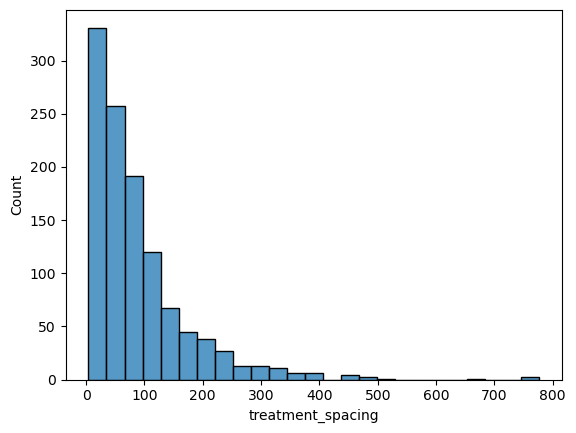

In [82]:
df['treatment_spacing'] =  abs(df['DX_CHEMO_STARTED_DAYS'] - df['DX_IMMUNO_STARTED_DAYS'])
sns.histplot(df['treatment_spacing'], bins=25)

In [83]:
best_cut_all = None
best_stat_all = 0

for cut in range(1, int(df['treatment_spacing'].max())):
    mask_low = df['treatment_spacing'] <= cut
    mask_high = df['treatment_spacing'] > cut
    if mask_low.sum() < (df.shape[0]*0.25) or mask_high.sum() < (df.shape[0]*0.25):
        continue  # avoid tiny groups
    results = logrank_test(
        df.loc[mask_low, 'time'],
        df.loc[mask_high, 'time'],
        event_observed_A=df.loc[mask_low, 'event'],
        event_observed_B=df.loc[mask_high, 'event']
    )
    if results.test_statistic > best_stat_all:
        best_stat_all = results.test_statistic
        best_cut_all = cut

print("Optimal cutpoint (days):", best_cut_all, "– log‐rank stat:", best_stat_all)

Optimal cutpoint (days): 95 – log‐rank stat: 20.86838792579934


In [84]:
spacings = ['spacing_binary', 'spacing_quartile', 'spacing_3090', 'spacing_week']

df['spacing_quartile'] = pd.qcut(df['treatment_spacing'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
df['spacing_3090'] = pd.cut(
    df['treatment_spacing'],
    bins=[-1, 30, 90, np.inf],
    labels=['≤30 days', '31–90 days', '>90 days']
)
df['spacing_week'] = pd.cut(
    df['treatment_spacing'],
    bins=[-1, 7, 14, 28, np.inf],
    labels=['≤7 days', '8–14 days', '15–28 days', '>28 days']
)
df['spacing_binary'] = (df['treatment_spacing'] > best_cut_all).astype(int).map({0: '≤' + str(best_cut_all) + ' days', 1: '>' + str(best_cut_all) + ' days'})


df_results2 = pd.DataFrame(columns=['Spacing Group', 'HR', 'CI Low', 'CI High', 'p-value', 'n'])

for spacing in spacings:
    for group in df[spacing].unique():
        group_mask = df[spacing] == group
        df_group = df[group_mask].copy()
        df_group = perform_iptw(df_group)

        cph = CoxPHFitter()
        cph.fit(
            df_group[['time', 'event', 'sequence_group', 'iptw_weight']],
            duration_col='time',
            event_col='event',
            weights_col='iptw_weight'
        )
        summary_df = cph.summary
        p_val = summary_df.loc['sequence_group', 'p'].round(4)
        hr = summary_df.loc['sequence_group', 'exp(coef)']
        ci_low = summary_df.loc['sequence_group', 'exp(coef) lower 95%']
        ci_high = summary_df.loc['sequence_group', 'exp(coef) upper 95%']
        n = df_group.shape[0]
        new_row = pd.DataFrame({
            'Spacing Group': [f"{spacing} - {group}"],
            'HR': [hr],
            'CI Low': [ci_low],
            'CI High': [ci_high],
            'p-value': [p_val],
            'n': [n]
        })
        df_results2 = pd.concat([df_results2, new_row], ignore_index=True)
    
    new_row = pd.DataFrame([{
        'Spacing Group': "",
        'HR': "",
        'CI Low': "",
        'CI High': "",
        'p-value': "",
        'n': ""
    }])
    df_results2 = pd.concat([df_results2, new_row], ignore_index=True)
        

df_results2


/var/folders/4r/chd7cdjn77j6krd2g7fstr3h0000gn/T/ipykernel_56571/914804646.py:46: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_results2 = pd.concat([df_results2, new_row], ignore_index=True)


,Spacing Group,HR,CI Low,CI High,p-value,n
0,spacing_binary - >95 days,0.951097,0.797054,1.134911,0.5781,362
1,spacing_binary - ≤95 days,0.808895,0.719468,0.909437,0.0004,773
2,,,,,,
3,spacing_quartile - Q3,1.155211,0.949499,1.405491,0.1493,283
4,spacing_quartile - Q4,0.870766,0.7133,1.062993,0.1739,282
5,spacing_quartile - Q1,0.844513,0.695162,1.025951,0.0888,292
6,spacing_quartile - Q2,0.698804,0.572594,0.852833,0.0004,278
7,,,,,,
8,spacing_3090 - >90 days,0.912197,0.769303,1.081632,0.2904,393
9,spacing_3090 - ≤30 days,0.83633,0.689764,1.01404,0.069,298


## Table 1

In [85]:
# import re

# # Define which group is which
# group_labels = {0: "TACE First", 1: "Systemic First"}
# df["Group"] = df["sequence_group"].map(group_labels)

# # Function to calculate weighted mean
# def weighted_mean(series, weights):
#     return np.average(series, weights=weights)

# # Build summary rows
# table_records = []

# manual_level_order = {
#     "COMBINED_STAGE_GROUP": [1, 2, 3, 4],
#     "Charlson_Deyo_Score": [0, 1, 2, 3],
#     "YEAR_OF_DIAGNOSIS": ["≤2017", "2018–2019", "2020+"]
# }

# for col in df.columns.difference(['iptw_weight', 'sequence_group', 'Group']):
#     if df[col].dtype == 'object' or df[col].nunique() <= 10:
#         levels = df[col].dropna().unique()

#         # Sort levels if this column is in the manual order dict
#         if col in manual_level_order:
#             order = manual_level_order[col]
#             # Sort according to manual order (string-matching for safety)
#             levels = sorted(levels, key=lambda x: order.index(x) if x in order else float('inf'))
#         else:
#             # Default: sort alphabetically
#             try:
#                 levels = sorted(levels, key=lambda x: int(re.findall(r'\d+', str(x))[0]) if re.search(r'\d+', str(x)) else str(x))
#             except:
#                 levels = sorted(levels)

#         smd_unweighted = asmd_df.set_index("Covariate").loc[col, "Unweighted"] if col in asmd_df["Covariate"].values else ""
#         smd_weighted = asmd_df.set_index("Covariate").loc[col, "IPTW"] if col in asmd_df["Covariate"].values else ""

#         for i, level in enumerate(levels):
#             record = {}
#             idx = (col, level)

#             for g in group_labels.values():
#                 mask = df["Group"] == g
#                 total = mask.sum()
#                 count = (df.loc[mask, col] == level).sum()
#                 pct = 100 * count / total

#                 weights = df.loc[mask, "iptw_weight"]
#                 count_wt = weights[df.loc[mask, col] == level].sum()
#                 pct_wt = 100 * count_wt / weights.sum()

#                 record[("Unweighted", g)] = f"{count} ({pct:.1f}%)"
#                 record[("IPTW", g)] = f"{count_wt:.1f} ({pct_wt:.1f}%)"

#             record[("Unweighted", "SMD")] = smd_unweighted if i == 0 else ""
#             record[("IPTW", "SMD")] = smd_weighted if i == 0 else ""

#             table_records.append((idx, record))

#     elif df[col].dtype in [np.float64, np.int64]:
#         smd_unweighted = asmd_df.set_index("Covariate").loc[col, "Unweighted"] if col in asmd_df["Covariate"].values else ""
#         smd_weighted = asmd_df.set_index("Covariate").loc[col, "IPTW"] if col in asmd_df["Covariate"].values else ""

#         record = {}
#         idx = (col, "mean (SD)")

#         for g in group_labels.values():
#             mask = df["Group"] == g

#             # Unweighted mean and std
#             mean = df.loc[mask, col].mean()
#             std = df.loc[mask, col].std()
#             record[("Unweighted", g)] = f"{mean:.2f} ({std:.2f})"

#             # Weighted mean and std
#             weights = df.loc[mask, "iptw_weight"]
#             weighted_avg = weighted_mean(df.loc[mask, col], weights)
#             weighted_var = np.average((df.loc[mask, col] - weighted_avg) ** 2, weights=weights)
#             weighted_std = np.sqrt(weighted_var)
#             record[("IPTW", g)] = f"{weighted_avg:.2f} ({weighted_std:.2f})"

#         record[("Unweighted", "SMD")] = smd_unweighted
#         record[("IPTW", "SMD")] = smd_weighted

#         table_records.append((idx, record))

# # Add the "Number" row as the first row
# number_record = {}
# for g in group_labels.values():
#     mask = df["Group"] == g
#     n_unweighted = mask.sum()
#     n_weighted = df.loc[mask, "iptw_weight"].sum()
#     number_record[("Unweighted", g)] = f"{n_unweighted}"
#     number_record[("IPTW", g)] = f"{n_weighted:.1f}"

# number_record[("Unweighted", "SMD")] = ""
# number_record[("IPTW", "SMD")] = ""

# # Insert at the top of the table
# table_records.insert(0, (("Number", ""), number_record))

# # Build MultiIndex DataFrame
# index_tuples, data = zip(*table_records)
# row_index = pd.MultiIndex.from_tuples(index_tuples, names=["Covariate", "Level"])
# columns = pd.MultiIndex.from_tuples(list(data[0].keys()), names=["Weighting", "Group"])

# formatted_table = pd.DataFrame(list(data), index=row_index, columns=columns)

# # Order the columns: unweighted columns and its SMD, then IPTW and its SMD
# unweighted_cols = [("Unweighted", g) for g in group_labels.values()] + [("Unweighted", "SMD")]
# iptw_cols = [("IPTW", g) for g in group_labels.values()] + [("IPTW", "SMD")]
# formatted_table = formatted_table[unweighted_cols + iptw_cols]

# manual_covariate_order = [
#     "Number", "AGE", "SEX", "RACE", "COMBINED_STAGE_GROUP", 
#     "Charlson_Deyo_Score", "YEAR_OF_DIAGNOSIS", "HISTOLOGY", 
#     "INSURANCE_STATUS"
# ]

# # Reindex to enforce the order on the outer level (Covariate)
# ordered_index = []
# for cov in manual_covariate_order:
#     matching = [idx for idx in formatted_table.index if idx[0] == cov]
#     ordered_index.extend(matching)

# formatted_table = formatted_table.loc[ordered_index]

# # Display in notebook
# formatted_table


In [86]:
# import xlsxwriter

# # Set output file path
# output_path = "entire_cohort_Table_1.xlsx"
# workbook = xlsxwriter.Workbook(output_path)
# worksheet = workbook.add_worksheet("Table 1")

# # Define formats
# bold_center = workbook.add_format({'bold': True, 'align': 'center', 'valign': 'vcenter'})
# bold_left = workbook.add_format({'bold': True, 'align': 'left', 'valign': 'vcenter'})
# center = workbook.add_format({'align': 'center', 'valign': 'vcenter'})
# gray_fill = workbook.add_format({'bg_color': '#f2f2f2', 'valign': 'vcenter', 'align': 'center'})
# gray_bold = workbook.add_format({'bg_color': '#f2f2f2', 'bold': True, 'valign': 'vcenter', 'align': 'left'})

# # Write table title
# worksheet.write(0, 0, "Table 1. Baseline Characteristic", bold_left)

# # Write "Characteristic" and "Level" headers
# worksheet.write(1, 0, "Characteristic", bold_center)
# worksheet.write(1, 1, "Level", bold_center)

# # Write column MultiIndex headers
# row_offset = 2
# col_offset = 2
# columns = formatted_table.columns
# row1 = []
# row2 = []

# for i, (outer, inner) in enumerate(columns):
#     worksheet.write(row_offset, col_offset + i, inner, bold_center)
#     row1.append(outer)
#     row2.append(inner)

# # Merge top-level header rows manually
# last_outer = None
# start_col = col_offset
# for i, outer in enumerate(row1):
#     if outer != last_outer:
#         if last_outer is not None:
#             worksheet.merge_range(row_offset - 1, start_col, row_offset - 1, col_offset + i - 1, last_outer, bold_center)
#         start_col = col_offset + i
#         last_outer = outer
# # Merge final group
# worksheet.merge_range(row_offset - 1, start_col, row_offset - 1, col_offset + len(row1) - 1, last_outer, bold_center)

# # Prepare to write data rows
# row_start = row_offset + 1
# row_groups = {}

# for i, (outer, inner) in enumerate(formatted_table.index):
#     row_idx = row_start + i
#     worksheet.write(row_idx, 1, inner, center)  # Level column
#     row_groups.setdefault(outer, []).append(row_idx)

# # Merge and format "Characteristic" column, and write data with shading
# for i, (cov, rows) in enumerate(row_groups.items()):
#     fmt = gray_bold if i % 2 == 0 else bold_left
#     shade_fmt = gray_fill if i % 2 == 0 else center

#     # Merge or write covariate name
#     if len(rows) == 1:
#         worksheet.write(rows[0], 0, cov, fmt)
#     else:
#         worksheet.merge_range(rows[0], 0, rows[-1], 0, cov, fmt)

#     # Write values
#     for r in rows:
#         # Shade level column
#         worksheet.write(r, 1, formatted_table.index[r - row_start][1], shade_fmt)
#         for c in range(formatted_table.shape[1]):
#             val = formatted_table.iloc[r - row_start, c]
#             worksheet.write(r, col_offset + c, val, shade_fmt)

# # Set column widths for nice layout
# worksheet.set_column(0, 0, 30)  # Characteristic
# worksheet.set_column(1, 1, 20)  # Level
# for c in range(col_offset, col_offset + formatted_table.shape[1]):
#     worksheet.set_column(c, c, 22)  # Data columns

# # Save the file
# workbook.close()
# print(f"✅ Saved formatted Excel file to: {output_path}")
